In [1]:
import pandas as pd

# Read both sheets of the Excel file (about 1 million rows, so this takes 2-5 minutes)
sheets = pd.read_excel("data/online_retail_II.xlsx", sheet_name=None)
df = pd.concat(sheets.values(), ignore_index=True)

# Save a CSV copy so later loads take seconds instead of minutes
df.to_csv("data/online_retail_II.csv", index=False)

print(df.shape)
df.head()

(1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [2]:
# From now on, load the fast CSV copy instead of the slow Excel file
df = pd.read_csv("data/online_retail_II.csv",
                 dtype={"Invoice": str, "StockCode": str},
                 parse_dates=["InvoiceDate"])

print("Total rows:", len(df))
print("\nMissing values per column:")
print(df.isna().sum())
print("\nCancelled invoices:", df["Invoice"].str.startswith("C").sum())
print("Rows with quantity or price <= 0:", ((df["Quantity"] <= 0) | (df["Price"] <= 0)).sum())
print("Duplicate rows:", df.duplicated().sum())

Total rows: 1067371

Missing values per column:
Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

Cancelled invoices: 19494
Rows with quantity or price <= 0: 25700
Duplicate rows: 34335


In [3]:
clean = df.copy()
print("Starting rows:", len(clean))

# 1. Remove cancelled orders (invoice starts with "C")
cancelled = clean["Invoice"].str.startswith("C")
print("Cancelled rows removed:", cancelled.sum())
clean = clean[~cancelled]

# 2. Remove rows with no Customer ID
missing_id = clean["Customer ID"].isna()
print("Rows missing Customer ID removed:", missing_id.sum())
clean = clean[~missing_id]

# 3. Remove zero or negative quantity/price
bad = (clean["Quantity"] <= 0) | (clean["Price"] <= 0)
print("Zero/negative quantity or price removed:", bad.sum())
clean = clean[~bad]

# 4. Remove exact duplicate rows
dups = clean.duplicated()
print("Duplicate rows removed:", dups.sum())
clean = clean[~dups]

# 5. Add a Revenue column and tidy the Customer ID
clean["Revenue"] = clean["Quantity"] * clean["Price"]
clean["Customer ID"] = clean["Customer ID"].astype(int)

print("\nClean rows:", len(clean))
print("Unique customers:", clean["Customer ID"].nunique())
print(f"Total revenue: £{clean['Revenue'].sum():,.0f}")

Starting rows: 1067371
Cancelled rows removed: 19494
Rows missing Customer ID removed: 242257
Zero/negative quantity or price removed: 71
Duplicate rows removed: 26124

Clean rows: 779425
Unique customers: 5878
Total revenue: £17,374,804


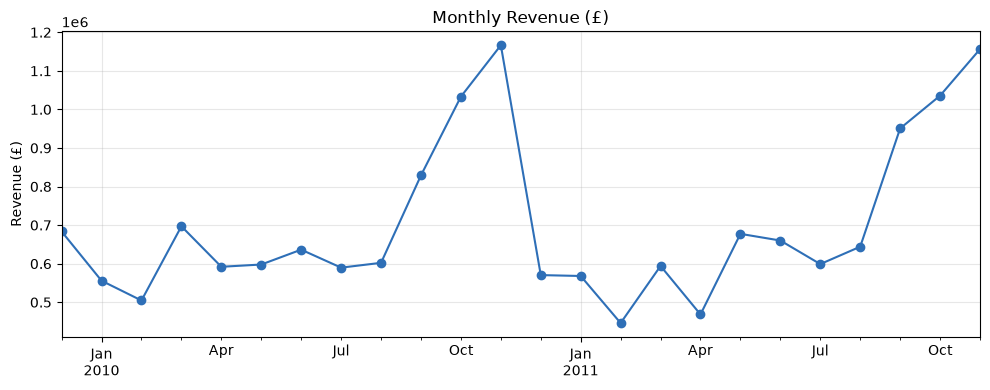

Best month: November 2010 £1,166,460
Worst month: February 2011 £446,085


In [4]:
import matplotlib.pyplot as plt

# The data stops on 9 Dec 2011, so leave out that partial month
full_months = clean[clean["InvoiceDate"] < "2011-12-01"]

monthly = full_months.set_index("InvoiceDate")["Revenue"].resample("MS").sum()

monthly.plot(figsize=(10, 4), marker="o", color="#2E6FB7")
plt.title("Monthly Revenue (£)")
plt.ylabel("Revenue (£)")
plt.xlabel("")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Best month:", monthly.idxmax().strftime("%B %Y"), f"£{monthly.max():,.0f}")
print("Worst month:", monthly.idxmin().strftime("%B %Y"), f"£{monthly.min():,.0f}")

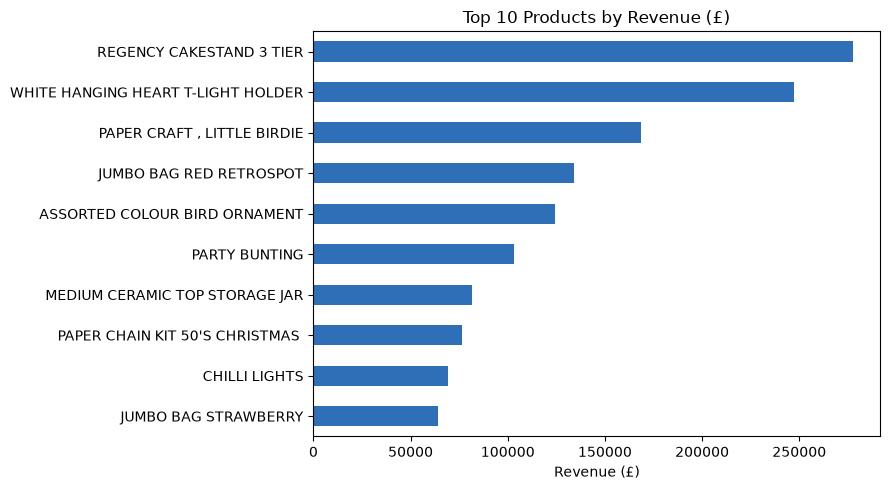

Top 10 products:
Description
REGENCY CAKESTAND 3 TIER              277656.0
WHITE HANGING HEART T-LIGHT HOLDER    247048.0
PAPER CRAFT , LITTLE BIRDIE           168470.0
JUMBO BAG RED RETROSPOT               134307.0
ASSORTED COLOUR BIRD ORNAMENT         124352.0
PARTY BUNTING                         103283.0
MEDIUM CERAMIC TOP STORAGE JAR         81417.0
PAPER CHAIN KIT 50'S CHRISTMAS         76598.0
CHILLI LIGHTS                          69084.0
JUMBO BAG STRAWBERRY                   64128.0
Name: Revenue, dtype: float64

UK share of revenue: 82.8%

Top 5 countries outside the UK:
Country
EIRE           616571.0
Netherlands    554038.0
Germany        425020.0
France         348769.0
Australia      169283.0
Name: Revenue, dtype: float64


In [6]:
# Keep real products only (their stock codes start with a number; fees like POST or M don't)
products_only = clean[clean["StockCode"].str[0].str.isdigit()]

top_products = (products_only.groupby("Description")["Revenue"]
                .sum().sort_values(ascending=False).head(10))

top_products.sort_values().plot(kind="barh", figsize=(9, 5), color="#2E6FB7")
plt.title("Top 10 Products by Revenue (£)")
plt.xlabel("Revenue (£)")
plt.ylabel("")
plt.tight_layout()
plt.show()

print("Top 10 products:")
print(top_products.round(0))

# Revenue by country
countries = clean.groupby("Country")["Revenue"].sum().sort_values(ascending=False)
uk_share = countries["United Kingdom"] / countries.sum() * 100
print(f"\nUK share of revenue: {uk_share:.1f}%")
print("\nTop 5 countries outside the UK:")
print(countries.drop("United Kingdom").head(5).round(0))

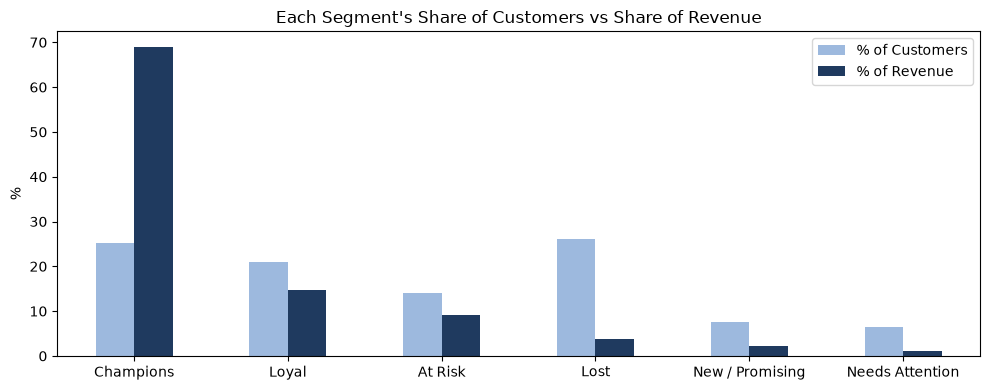

,Customers,Revenue,Avg_Days_Since_Last_Order,Avg_Orders,% of Customers,% of Revenue
Segment,,,,,,
Champions,1473,11983421.7,20.1,15.7,25.1,69.0
Loyal,1229,2549954.5,78.3,5.4,20.9,14.7
At Risk,825,1590384.6,368.9,4.9,14.0,9.2
Lost,1526,655444.7,458.7,1.3,26.0,3.8
New / Promising,441,391838.3,28.0,1.5,7.5,2.3
Needs Attention,384,203760.5,106.2,1.4,6.5,1.2


In [7]:
# "Today" for the analysis = the day after the last order in the data
snapshot = clean["InvoiceDate"].max() + pd.Timedelta(days=1)

# One row per customer with their R, F and M values
rfm = clean.groupby("Customer ID").agg(
    Recency=("InvoiceDate", lambda d: (snapshot - d.max()).days),
    Frequency=("Invoice", "nunique"),
    Monetary=("Revenue", "sum"),
)

# Score each from 1 (worst) to 5 (best) by splitting customers into 5 equal groups
rfm["R"] = pd.qcut(rfm["Recency"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["F"] = pd.qcut(rfm["Frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M"] = pd.qcut(rfm["Monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)

# Turn scores into business-friendly segments
def segment(row):
    r, f = row["R"], row["F"]
    if r >= 4 and f >= 4: return "Champions"
    if r >= 3 and f >= 3: return "Loyal"
    if r >= 4 and f <= 2: return "New / Promising"
    if r <= 2 and f >= 3: return "At Risk"
    if r <= 2 and f <= 2: return "Lost"
    return "Needs Attention"

rfm["Segment"] = rfm.apply(segment, axis=1)

# Summary table: size and value of each segment
summary = rfm.groupby("Segment").agg(
    Customers=("Monetary", "size"),
    Revenue=("Monetary", "sum"),
    Avg_Days_Since_Last_Order=("Recency", "mean"),
    Avg_Orders=("Frequency", "mean"),
)
summary["% of Customers"] = summary["Customers"] / summary["Customers"].sum() * 100
summary["% of Revenue"] = summary["Revenue"] / summary["Revenue"].sum() * 100
summary = summary.sort_values("Revenue", ascending=False).round(1)

summary[["% of Customers", "% of Revenue"]].plot(kind="bar", figsize=(10, 4), color=["#9DB9DE", "#1F3A5F"])
plt.title("Each Segment's Share of Customers vs Share of Revenue")
plt.ylabel("%")
plt.xlabel("")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

summary